# Language Identification: Classifier Comparison (Macro-F1)

Dataset: **the same IndicCorpV2 sentence dataset pipeline used in the earlier lab** (stream `ai4bharat/IndicCorpV2` -> paragraphs -> sentences with `indic-nlp-library` -> dedup -> 3-100 word filter -> length-stratified 1000 dev / 1000 test), built for several Indic languages so it can be used for language identification. If your Gujarati splits (`train_1000000.txt`, `dev.txt`, `test.txt`) are already on disk from that lab, they are reused as-is.
Embeddings: FastText **wiki** vectors (one file per language).

**Fully automatic:** just run all cells - the IndicCorpV2 sample and the FastText wiki vectors are downloaded on the fly (and cached, so reruns are instant).

Classifiers compared:
1. Logistic Regression on averaged word vectors
2. MLP with n = 0, 1, 2 hidden layers
3. LSTM
4. GRU
5. FastText supervised classifier

Evaluation: **macro-F1 implemented from scratch** (no `sklearn.metrics`, no sklearn classes).

In [1]:
!pip -q install "datasets==2.19.2" huggingface_hub fasttext-wheel torch numpy pandas tqdm indic-nlp-library

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.1/542.1 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 95.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 99.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.1/121.1 kB 6.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.3.1 which is inco

In [2]:
import os, re, time, string, math, random, urllib.request
from collections import defaultdict
import numpy as np, pandas as pd
import torch, torch.nn as nn
from tqdm.auto import tqdm

# ============ CONFIG: edit these ============
HF_DATASET = "ai4bharat/IndicCorpV2"
TRAIN_PER_LANG = 10_000       # train sentences per language (the earlier lab used up to 1,000,000 for ONE language)
DEV_SIZE       = 1000         # dev sentences per language  (same as earlier lab)
TEST_SIZE      = 1000         # test sentences per language (same as earlier lab)
MIN_WORDS, MAX_SENT_WORDS = 3, 100     # sentence-length sanity filter (same as earlier lab)
POOL_BUFFER    = 5000         # extra sentences collected so dev/test stratified sampling has room
SHUFFLE_STREAM = True         # shuffle the HF stream (buffered) so we don't only get the first few articles
SHUFFLE_BUFFER = 10_000
REUSE_EXISTING_GUJARATI = True   # reuse train/dev/test .txt from the earlier lab if found on disk

OUT_DIR = "/kaggle/working/indiccorp_experiment" if os.path.exists("/kaggle/working") else "indiccorp_experiment"
os.makedirs(OUT_DIR, exist_ok=True)

MAX_WORDS_PER_LANG = 50000    # top-N most frequent words read from each wiki.<lang>.vec
EMB_DIM     = 300
MAX_LEN     = 50              # max tokens per sentence for LSTM/GRU
HIDDEN      = 256
EPOCHS      = 15
BATCH       = 128
LR          = 1e-3
SEED        = 42
VEC_DIR     = os.path.join(OUT_DIR, "vectors")

# IndicCorpV2 split name -> ISO / fastText wiki-vector code (same code is used for indic-nlp sentence splitting).
# Languages without official wiki vectors (brx, doi, gom, kas, mai, mni, khasi, santhali) are left out;
# add them if you like - missing vector files are skipped with a warning.
LANGS = {
 "asm_Beng":"as", "ben_Beng":"bn", "guj_Gujr":"gu", "hin_Deva":"hi", "kan_Knda":"kn",
 "mal_Mlym":"ml", "mar_Deva":"mr", "npi_Deva":"ne", "ory_Orya":"or", "pan_Guru":"pa",
 "san_Deva":"sa", "snd_Deva":"sd", "tam_Taml":"ta", "tel_Telu":"te", "urd_Arab":"ur",
}
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| OUT_DIR:", OUT_DIR)

device: cuda | OUT_DIR: /kaggle/working/indiccorp_experiment


## 1. Build the IndicCorpV2 language-ID dataset (same pipeline as the earlier lab)

In [3]:
from datasets import load_dataset
try:
    from indicnlp.tokenize import sentence_tokenize
    INDIC_NLP_AVAILABLE = True
except ImportError:
    INDIC_NLP_AVAILABLE = False
    print("indic-nlp-library not available, using regex sentence splitter only.")

# Regex fallback: split after Indic danda, double danda, or . ! ?
_SENT_END_RE = re.compile(r'(?<=[।॥.!?])\s+')

def split_sentences(paragraph, iso_code):
    if INDIC_NLP_AVAILABLE and iso_code:
        try:
            sents = [s.strip() for s in sentence_tokenize.sentence_split(paragraph, lang=iso_code) if s.strip()]
            if sents: return sents
        except Exception:
            pass
    return [s.strip() for s in _SENT_END_RE.split(paragraph) if s.strip()]

def word_count(s): return len(s.split())

CHUNK_BYTES = 1024 * 1024
_REPO_FILES = None

def repo_data_files():
    global _REPO_FILES
    if _REPO_FILES is None:
        from huggingface_hub import HfApi
        _REPO_FILES = [f for f in HfApi().list_repo_files(HF_DATASET, repo_type="dataset") if f.startswith("data/")]
    return _REPO_FILES

def files_for_language(iso):
    # README maps splits to raw files: data/as.txt, data/gu.txt, ..., Hindi -> data/hi-*.txt (several shards)
    out = []
    for f in repo_data_files():
        stem = f.split("/")[-1].split(".")[0]
        if stem == iso or stem.startswith(iso + "-") or stem.startswith(iso + "_"):
            out.append(f)
    return sorted(out)

def stream_from_hub_files(lang_split, iso):
    # Fallback that bypasses the `datasets` config: random byte-range reads from the raw text files on the Hub.
    from huggingface_hub import HfFileSystem
    files = files_for_language(iso)
    if not files:
        raise RuntimeError(f"no data/{iso}*.txt files in the repo. Files seen under data/: {repo_data_files()[:40]}")
    fs = HfFileSystem(); rnd = random.Random(SEED)
    sizes = {f: fs.info(f"datasets/{HF_DATASET}/{f}")["size"] for f in files}
    print(f"  [{lang_split}] reading raw files directly: {files}")
    for _ in range(100000):
        f = rnd.choice(files)
        off = rnd.randint(0, max(0, sizes[f] - CHUNK_BYTES))
        with fs.open(f"datasets/{HF_DATASET}/{f}", "rb") as fh:
            fh.seek(off); chunk = fh.read(CHUNK_BYTES)
        lines = chunk.decode("utf-8", "ignore").split(chr(10))[1:-1]    # drop partial first/last line
        rnd.shuffle(lines)
        for t in lines:
            t = t.strip()
            if t: yield t

def stream_raw_paragraphs(lang_split):
    # 1) same loading strategy as the earlier lab (works for most languages)
    errs = []
    for kwargs in (
        dict(path=HF_DATASET, name="indiccorp_v2", split=lang_split, streaming=True),
        dict(path=HF_DATASET, name="indiccorp_v2", data_dir=f"data/{lang_split}", split="train", streaming=True),
    ):
        try:
            ds = load_dataset(**kwargs)
            if SHUFFLE_STREAM:
                ds = ds.shuffle(seed=SEED, buffer_size=SHUFFLE_BUFFER)
            for row in ds:
                text = (row.get("text") or row.get("Text") or next(iter(row.values())) or "").strip()
                if text: yield text
            return
        except Exception as e:
            errs.append(f"{type(e).__name__}: {str(e)[:160]}")
    # 2) fallback: read the raw files straight from the Hub (e.g. hin_Deva is sharded as data/hi-*.txt)
    print(f"  [{lang_split}] datasets loader failed -> using direct file reader")
    try:
        yield from stream_from_hub_files(lang_split, LANGS[lang_split])
    except Exception as e:
        raise RuntimeError(f"Could not read '{lang_split}'. datasets errors: {errs} | direct reader error: {e}")

def build_sentence_pool(lang_split, iso, target_count):
    seen, sentences = set(), []
    pbar = tqdm(total=target_count, desc=f"{lang_split}", leave=False)
    for para in stream_raw_paragraphs(lang_split):
        for sent in split_sentences(para, iso):
            wc = word_count(sent)
            if wc < MIN_WORDS or wc > MAX_SENT_WORDS or sent in seen: continue
            seen.add(sent); sentences.append(sent); pbar.update(1)
            if len(sentences) >= target_count:
                pbar.close(); return sentences
    pbar.close()
    print(f"WARNING: {lang_split} exhausted early with {len(sentences)} sentences (wanted {target_count}).")
    return sentences

BIN_EDGES = [0, 5, 10, 15, 20, 25, 30, 40, 50, 70, 100, 1000]

def stratified_sample_indices(bin_ids, n_total, rnd, exclude=None):
    # dev/test length distribution mirrors the pool (same method as the earlier lab)
    exclude = exclude or set()
    by_bin = defaultdict(list)
    for idx, b in enumerate(bin_ids):
        if idx not in exclude: by_bin[b].append(idx)
    total_pool = sum(len(v) for v in by_bin.values())
    raw_alloc = {b: len(v) / total_pool * n_total for b, v in by_bin.items()}
    alloc = {b: int(math.floor(v)) for b, v in raw_alloc.items()}
    remainder = n_total - sum(alloc.values())
    fracs = sorted(raw_alloc.items(), key=lambda kv: kv[1] - math.floor(kv[1]), reverse=True)
    i = 0
    while remainder > 0 and i < len(fracs):
        b = fracs[i][0]
        if alloc[b] < len(by_bin[b]): alloc[b] += 1; remainder -= 1
        i += 1
    selected = []
    for b, count in alloc.items():
        selected.extend(rnd.sample(by_bin[b], min(count, len(by_bin[b]))))
    rnd.shuffle(selected)
    return set(selected)

def build_language(lang_split, iso):
    rnd = random.Random(SEED)
    pool = build_sentence_pool(lang_split, iso, TRAIN_PER_LANG + DEV_SIZE + TEST_SIZE + POOL_BUFFER)
    lengths = np.array([word_count(s) for s in pool])
    bin_ids = np.digitize(lengths, BIN_EDGES)
    dev_idx  = stratified_sample_indices(bin_ids, DEV_SIZE, rnd)
    test_idx = stratified_sample_indices(bin_ids, TEST_SIZE, rnd, exclude=dev_idx)
    rest = [i for i in range(len(pool)) if i not in dev_idx and i not in test_idx]
    rnd.shuffle(rest)
    return ([pool[i] for i in rest[:TRAIN_PER_LANG]], [pool[i] for i in dev_idx], [pool[i] for i in test_idx])

def read_lines(path):
    with open(path, encoding="utf-8") as f: return [l.rstrip("\n") for l in f if l.strip()]

def load_existing_gujarati():
    # splits written by the earlier lab (tokenization / LM / embeddings notebook)
    dev_p, test_p = os.path.join(OUT_DIR, "dev.txt"), os.path.join(OUT_DIR, "test.txt")
    for name in ("train_1000000.txt", "train_pool_full.txt", "train_500000.txt", "train_300000.txt", "train_100000.txt"):
        tr_p = os.path.join(OUT_DIR, name)
        if os.path.exists(tr_p) and os.path.exists(dev_p) and os.path.exists(test_p):
            return read_lines(tr_p)[:TRAIN_PER_LANG], read_lines(dev_p)[:DEV_SIZE], read_lines(test_p)[:TEST_SIZE]
    return None

In [4]:
CACHE_CSV = os.path.join(OUT_DIR, "langid_dataset.csv")
df = None
if os.path.exists(CACHE_CSV):
    _c = pd.read_csv(CACHE_CSV)
    if set(_c["label"].unique()) == set(LANGS) and _c[_c.split == "train"].groupby("label").size().min() >= 0.9 * TRAIN_PER_LANG:
        df = _c; print("loaded cached dataset:", CACHE_CSV)

if df is None:
    rows = []
    for lang, iso in LANGS.items():
        existing = load_existing_gujarati() if (REUSE_EXISTING_GUJARATI and lang == "guj_Gujr") else None
        if existing:
            tr, dv, te = existing; print(f"{lang}: reusing splits from the earlier lab")
        else:
            tr, dv, te = build_language(lang, iso)
        print(f"{lang}: train={len(tr)} dev={len(dv)} test={len(te)}")
        rows += [(t, lang, "train") for t in tr] + [(t, lang, "dev") for t in dv] + [(t, lang, "test") for t in te]
    df = pd.DataFrame(rows, columns=["text", "label", "split"])
    df.to_csv(CACHE_CSV, index=False)

print(df.shape)
display(df.groupby(["label", "split"]).size().unstack())
df.sample(5, random_state=0)

asm_Beng:   0%|          | 0/17000 [00:00<?, ?it/s]

asm_Beng: train=10000 dev=1000 test=1000


ben_Beng:   0%|          | 0/17000 [00:00<?, ?it/s]

ben_Beng: train=10000 dev=1000 test=1000


guj_Gujr:   0%|          | 0/17000 [00:00<?, ?it/s]

...

tel_Telu: train=10000 dev=1000 test=1000


urd_Arab:   0%|          | 0/17000 [00:00<?, ?it/s]

urd_Arab: train=10000 dev=1000 test=1000
(180000, 3)


split,dev,test,train
label,,,
asm_Beng,1000,1000,10000
ben_Beng,1000,1000,10000
guj_Gujr,1000,1000,10000
hin_Deva,1000,1000,10000
kan_Knda,1000,1000,10000
mal_Mlym,1000,1000,10000
mar_Deva,1000,1000,10000
npi_Deva,1000,1000,10000
ory_Orya,1000,1000,10000


,text,label,split
91036,"लेआउटको प्रकार एक क्लासिक किताब, यूरोबक्स , डल...",npi_Deva,train
59238,ಪೂನಾಕ್ಕೆ ಕೆಲಸಕ್ಕಾಗಿ ತೆರಳುತ್ತಿದ್ದರು ಎಂದು ಒಂದು ಮ...,kan_Knda,test
149078,"""பணியிடை நீக்கம் செய்யப்பட்டதும், 'உங்களுக்காக...",tam_Taml,train
31550,“નહીં. પરંતુ નિશ્ચિત રીતે અમે IPL દરમિયાન તેમન...,guj_Gujr,train
155877,ஜனாதிபதி நிறைவேற்று அதிகாரத்தை குறைப்பதற்கே ஐ....,tam_Taml,test


In [5]:
labels = sorted(df["label"].unique())
label2id = {l:i for i,l in enumerate(labels)}
id2label = {i:l for l,i in label2id.items()}
C = len(labels)
print(C, "languages:", labels)

# NOTE: Python's \\w does not match Indic combining vowel signs, so we split on whitespace and strip punctuation instead.
PUNCT = string.punctuation + "\u0964\u0965\u2018\u2019\u201c\u201d\u2013\u2014\u2026\u00bb\u00ab\u060c\u061f\u06d4"
def tokenize(t):
    toks = [w.strip(PUNCT) for w in t.lower().split()]
    return [w for w in toks if w]

texts = df["text"].astype(str).tolist()
y_all = np.array([label2id[l] for l in df["label"]])

# use the dataset's own train / dev / test splits (no re-splitting)
tr_idx = np.where(df["split"].values == "train")[0]
va_idx = np.where(df["split"].values == "dev")[0]
te_idx = np.where(df["split"].values == "test")[0]
print("train/val/test:", len(tr_idx), len(va_idx), len(te_idx))

15 languages: ['asm_Beng', 'ben_Beng', 'guj_Gujr', 'hin_Deva', 'kan_Knda', 'mal_Mlym', 'mar_Deva', 'npi_Deva', 'ory_Orya', 'pan_Guru', 'san_Deva', 'snd_Deva', 'tam_Taml', 'tel_Telu', 'urd_Arab']
train/val/test: 150000 15000 15000


## 2. Macro-F1 from scratch

In [6]:
def macro_f1(y_true, y_pred, n_classes):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    f1s = []
    for c in range(n_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        denom = 2*tp + fp + fn
        f1s.append(2*tp/denom if denom > 0 else 0.0)
    return float(np.mean(f1s))

## 3. FastText wiki vectors
For every language in the dataset we stream the first `MAX_WORDS_PER_LANG` lines of `wiki.<lang>.vec`
(files are frequency-sorted, so we don't have to download the multi-GB file), keep only words that occur in our dataset,
and merge them into one lookup table. Words missing from every language file are treated as OOV (zero vector, ignored in averaging).

> Note: the per-language wiki vector spaces are not aligned with each other. We merge by word, which does **not** use the gold label (no leakage).
> Several languages share Devanagari (Hindi, Marathi, Nepali, Sanskrit, Sindhi-Deva), so shared words get the vector of whichever language file is loaded first.

In [7]:
os.makedirs(VEC_DIR, exist_ok=True)
codes = sorted({LANGS[l] for l in labels})
print("language codes:", codes)

def get_vec_lines(code, n):
    cache = f"{VEC_DIR}/wiki.{code}.top{n}.vec"
    if not os.path.exists(cache):
        url = f"https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{code}.vec"
        print("streaming", url)
        ok = False
        for attempt in range(3):
            try:
                with urllib.request.urlopen(url, timeout=60) as r, open(cache + ".tmp", "wb") as out:
                    r.readline()  # header
                    for _ in range(n):
                        line = r.readline()
                        if not line: break
                        out.write(line)
                os.replace(cache + ".tmp", cache); ok = True; break   # atomic: never leave a half-written cache
            except Exception as e:
                print(f"  retry {attempt+1}/3 for {code}: {e}"); time.sleep(3)
        if not ok:
            print("  !! skipping", code, "(no wiki vectors available)")
            if os.path.exists(cache + ".tmp"): os.remove(cache + ".tmp")
            return []
    with open(cache, encoding="utf-8", errors="ignore") as f:
        return f.readlines()

# words we actually need
needed = set()
for t in texts: needed.update(tokenize(t))
print("unique tokens in dataset:", len(needed))

word2idx = {"<pad>":0, "<unk>":1}
vecs = [np.zeros(EMB_DIM, np.float32), np.zeros(EMB_DIM, np.float32)]
for code_ in tqdm(codes):
    for line in get_vec_lines(code_, MAX_WORDS_PER_LANG):
        parts = line.rstrip().split(" ")
        w = parts[0].lower()
        if w in needed and w not in word2idx and len(parts) >= EMB_DIM + 1:
            word2idx[w] = len(vecs)
            vecs.append(np.asarray(parts[1:EMB_DIM+1], dtype=np.float32))
emb_matrix = np.stack(vecs)
print("vocab with vectors:", len(word2idx), "| coverage of dataset tokens: %.1f%%" % (100*(len(word2idx)-2)/len(needed)))

language codes: ['as', 'bn', 'gu', 'hi', 'kn', 'ml', 'mr', 'ne', 'or', 'pa', 'sa', 'sd', 'ta', 'te', 'ur']
unique tokens in dataset: 531744


  0%|          | 0/15 [00:00<?, ?it/s]

streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.as.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.bn.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.gu.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.hi.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.kn.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.ml.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.mr.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.ne.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.or.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.pa.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.sa.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.sd.vec
streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.ta.vec
streaming https://dl.fbai

## 4. Build features (averaged vectors) and token-id sequences

In [8]:
def to_ids(t):
    ids = [word2idx.get(w, 1) for w in tokenize(t)][:MAX_LEN]
    return ids if ids else [1]

seqs = [to_ids(t) for t in texts]
lens = np.array([len(s) for s in seqs])
X_ids = np.zeros((len(seqs), MAX_LEN), dtype=np.int64)
for i, s in enumerate(seqs): X_ids[i, :len(s)] = s

# averaged word vectors (ignore pad/unk)
def avg_features(ids_arr):
    E = emb_matrix[ids_arr]                       # N, L, D
    mask = (ids_arr > 1)[..., None].astype(np.float32)
    return (E * mask).sum(1) / np.maximum(mask.sum(1), 1)
X_avg = avg_features(X_ids).astype(np.float32)

def T(x, dt=None): return torch.tensor(x, dtype=dt).to(device)
splits = {k: dict(avg=T(X_avg[ix]), ids=T(X_ids[ix]), len=T(lens[ix]), y=T(y_all[ix]))
          for k, ix in dict(train=tr_idx, val=va_idx, test=te_idx).items()}

## 5. Models + training loop

In [9]:
class MLP(nn.Module):
    def __init__(self, n_hidden, d_in=EMB_DIM, h=HIDDEN, out=C):
        super().__init__()
        layers, d = [], d_in
        for _ in range(n_hidden):
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(0.2)]; d = h
        layers.append(nn.Linear(d, out))      # n_hidden=0  ->  plain logistic (softmax) regression
        self.net = nn.Sequential(*layers)
    def forward(self, avg, ids=None, lens=None): return self.net(avg)

class RNNClf(nn.Module):
    def __init__(self, kind, h=128):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=True, padding_idx=0)
        rnn = nn.LSTM if kind == "lstm" else nn.GRU
        self.kind = kind
        self.rnn = rnn(EMB_DIM, h, batch_first=True)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(h, C)
    def forward(self, avg, ids, lens):
        x = self.emb(ids)
        packed = nn.utils.rnn.pack_padded_sequence(x, lens.cpu().clamp(min=1), batch_first=True, enforce_sorted=False)
        _, hN = self.rnn(packed)
        h = hN[0][-1] if self.kind == "lstm" else hN[-1]
        return self.fc(self.drop(h))

@torch.no_grad()
def predict(model, d):
    model.eval(); out = []
    for i in range(0, len(d["y"]), 512):
        s = slice(i, i+512)
        out.append(model(d["avg"][s], d["ids"][s], d["len"][s]).argmax(1).cpu())
    return torch.cat(out).numpy()

def train_eval(model, name, epochs=EPOCHS):
    model.to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)
    lossf = nn.CrossEntropyLoss()
    tr = splits["train"]; n = len(tr["y"])
    best_val, best_test, t0 = -1, 0, time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=device)
        for i in range(0, n, BATCH):
            b = perm[i:i+BATCH]
            loss = lossf(model(tr["avg"][b], tr["ids"][b], tr["len"][b]), tr["y"][b])
            opt.zero_grad(); loss.backward(); opt.step()
        v = macro_f1(splits["val"]["y"].cpu().numpy(), predict(model, splits["val"]), C)
        if v > best_val:   # model selection on validation macro-F1
            best_val = v
            best_test = macro_f1(splits["test"]["y"].cpu().numpy(), predict(model, splits["test"]), C)
    print(f"{name:28s} val F1={best_val:.4f}  test F1={best_test:.4f}  ({time.time()-t0:.0f}s)")
    return best_test

results = {}

## 6. Run all classifiers

In [10]:
# 1 + 2. Logistic regression (= MLP with 0 hidden layers) and MLPs with 1, 2 hidden layers
results["Logistic Regression (avg vecs)"] = train_eval(MLP(0), "Logistic Regression (avg vecs)")
for n_h in (0, 1, 2):
    results[f"MLP (n_hidden={n_h})"] = train_eval(MLP(n_h), f"MLP (n_hidden={n_h})")

# 3. LSTM
results["LSTM"] = train_eval(RNNClf("lstm"), "LSTM")

# 4. GRU
results["GRU"] = train_eval(RNNClf("gru"), "GRU")

Logistic Regression (avg vecs) val F1=0.9916  test F1=0.9910  (18s)
MLP (n_hidden=0)             val F1=0.9916  test F1=0.9910  (17s)
MLP (n_hidden=1)             val F1=0.9924  test F1=0.9919  (23s)
MLP (n_hidden=2)             val F1=0.9924  test F1=0.9915  (28s)
LSTM                         val F1=0.9938  test F1=0.9931  (83s)
GRU                          val F1=0.9934  test F1=0.9932  (79s)


## 7. FastText supervised classification (fasttext library)

In [12]:
import fasttext

def ft_label(i): return "__label__" + id2label[y_all[i]].replace(" ", "_")
def ft_text(i):  return " ".join(tokenize(texts[i]))

for name, ix in [("train", tr_idx), ("valid", va_idx)]:
    with open(f"ft_{name}.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(f"{ft_label(i)} {ft_text(i)}" for i in ix) + "\n")

ft = fasttext.train_supervised(input="ft_train.txt", epoch=25, lr=0.5, wordNgrams=2, dim=100, verbose=0)

# exact label-string -> id map (labels like 'guj_Gujr' already contain '_')
ft_label2id = {"__label__" + l.replace(" ", "_"): i for l, i in label2id.items()}

def ft_predict_label(text):
    # ft.predict() crashes with NumPy 2.x, so call the C++ binding directly
    preds = ft.f.predict((text or "x") + "\n", 1, 0.0, "strict")
    return preds[0][1] if preds else None

pred_labels = [ft_predict_label(ft_text(i)) for i in te_idx]
y_pred = np.array([ft_label2id.get(l, -1) for l in pred_labels])   # -1 = no prediction (counted as wrong)
results["FastText (supervised)"] = macro_f1(y_all[te_idx], y_pred, C)
print("FastText test macro-F1:", round(results["FastText (supervised)"], 4))

FastText test macro-F1: 0.9633


## 8. Comparison

,Classifier,Macro-F1
0,GRU,0.9932
1,LSTM,0.9931
2,MLP (n_hidden=1),0.9919
3,MLP (n_hidden=2),0.9915
4,Logistic Regression (avg vecs),0.9910
5,MLP (n_hidden=0),0.9910
6,FastText (supervised),0.9633


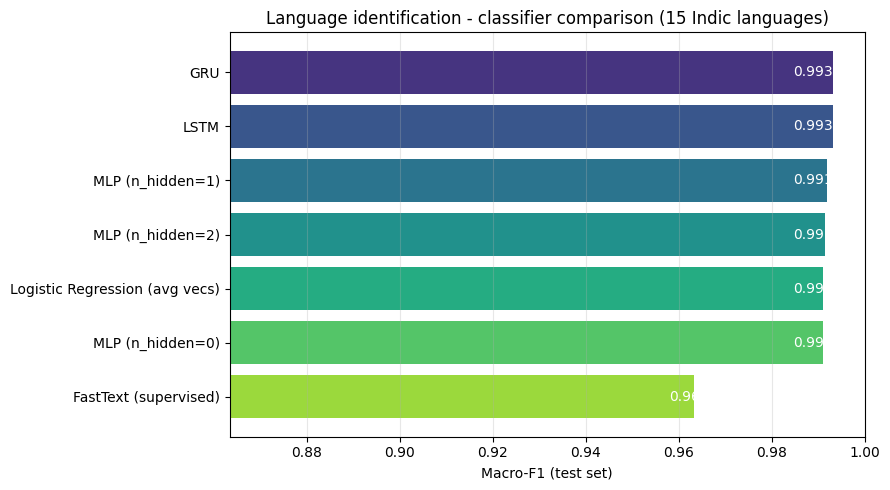

In [14]:
import matplotlib.pyplot as plt

res = (pd.DataFrame({"Classifier": list(results), "Macro-F1": list(results.values())})
         .sort_values("Macro-F1", ascending=False).reset_index(drop=True))
display(res.round(4))
res.to_csv(os.path.join(OUT_DIR, "macro_f1_results.csv"), index=False)

fig, ax = plt.subplots(figsize=(9, 5))
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(res)))
bars = ax.barh(res["Classifier"], res["Macro-F1"], color=colors)
ax.invert_yaxis()                                   # best classifier on top
lo = max(0.0, res["Macro-F1"].min() - 0.1)          # zoom so small differences are visible
ax.set_xlim(lo, 1.0)
for b, v in zip(bars, res["Macro-F1"]):
    ax.text(min(v + 0.005, 0.995), b.get_y() + b.get_height() / 2, f"{v:.4f}",
            va="center", ha="left" if v < 0.95 else "right",
            color="black" if v < 0.95 else "white", fontsize=10)
ax.set_xlabel("Macro-F1 (test set)")
ax.set_title(f"Language identification - classifier comparison ({C} Indic languages)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "macro_f1_comparison.png"), dpi=150)
plt.show()

## 9. Discussion 
- Which classifier gave the best macro-F1 and why? (FastText's character n-gram subwords / bigrams usually help a lot for language ID.)
- Effect of adding hidden layers (n = 0, 1, 2) over plain averaging.
- Sequence models (LSTM/GRU) vs. bag-of-vectors: does word order matter for language identification?
- Which languages were most confused? Expect Hindi/Marathi/Nepali/Sanskrit (all Devanagari) to be hardest. (Easy extension: build a confusion matrix manually with NumPy.)